In [3]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
import scanpy as sc
from tqdm import tqdm
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler

from Henosis.dataprocess.h5a import H5ADTokenizer
from Henosis.const import set_species_context
from Henosis import data
import Henosis.resa as resa
import Henosis.utils as utils
import Henosis.mmd as mmd
import Henosis.lr_schedule as lr_sche
import Henosis.henosis as henosis

In [8]:
organ='motor'

In [12]:
PROJECT_ROOT = Path.cwd()
DATA_ROOT = Path(
    os.environ.get("HENOSIS_DATA_DIR", PROJECT_ROOT / "data")
).expanduser()

DATA_DIR = f"{DATA_ROOT}/figure2/{organ}"

In [ ]:
species_to_adata = {
    "homo_sapiens": sc.read_h5ad(f"{DATA_DIR}/scrna/{organ}/homo_sapiens.h5ad"),
    "Mus_musculus": sc.read_h5ad(f"{DATA_DIR}/scrna/{organ}/Mus_musculus.h5ad"),
    "Macaca_mulatta": sc.read_h5ad(f"{DATA_DIR}/scrna/{organ}/Macaca_mulatta.h5ad"),
    "Callithrix_jacchus": sc.read_h5ad(f"{DATA_DIR}/scrna/{organ}/Callithrix_jacchus.h5ad"),
}

In [ ]:
species_to_embed_file = {
    "homo_sapiens": f"{DATA_DIR}/embedding/{organ}/homo_sapiens.avg.embeddings",
    "Mus_musculus": f"{DATA_DIR}/embedding/{organ}/Mus_musculus.avg.embeddings",
    "Macaca_mulatta": f"{DATA_DIR}/embedding/{organ}/Macaca_mulatta.avg.embeddings",
    "Callithrix_jacchus": f"{DATA_DIR}/embedding/{organ}/Callithrix_jacchus.avg.embeddings",
}

In [16]:
species_dict=set_species_context(species_to_adata)
token_species_dict={v:k for k,v in species_dict.items()}

In [17]:
tokenized = H5ADTokenizer(
    species_to_adata,
    species_to_embed_file,
).process_species_adata()

100%|██████████| 34310/34310 [00:01<00:00, 22745.15it/s]


In [18]:
species_to_reps = {
    "homo_sapiens": "X_pca",
    "Mus_musculus": "X_pca",
    "Macaca_mulatta": "X_pca",
    "Callithrix_jacchus": "X_pca",
}

In [19]:
train_loader, test_loader = data.prepare_multispecies_dataloaders(
    tokenized,
    batch_size=512,
    species_to_reps=species_to_reps,
    batch_species=len(tokenized),
)

homo_sapiens: X_pca
Mus_musculus: X_pca
Macaca_mulatta: X_pca
Callithrix_jacchus: X_pca


In [20]:
d_model=120
embed_size=480
scale=4
input_size=50
latent_size=64
num_layers=1
n_clusters=100000
net=henosis.Henosis(species_to_embed_file,d_model,embed_size,latent_size,encoder_type='mean_pool')

PCA ing
PCA done


In [21]:
def train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,current_temp,scheduler,ml_weight=1.0):
    net.train()
    metrics=utils.Accumulator(4)
    pbar=tqdm(train_loader,desc='Processing')
    for _,batch in enumerate(pbar):
        optimizer.zero_grad(set_to_none=True)

        data,adata,sp=batch
        data = data.to(device, non_blocking=True)
        adata = adata.float().to(device, non_blocking=True)
        sp = sp.to(device, non_blocking=True)

        with autocast('cuda'):
            sl = torch.tensor(0.0, device=device)
            protein_features,gene_features,logit_scales=net(adata,data,sp,)
            species_ids = torch.unique(sp).tolist()
            #for i in torch.unique(sp):
            for s in species_ids:
                mask = (sp == s)

                indices = torch.nonzero(mask).squeeze(1)
                protein_features_i = torch.index_select(protein_features, 0, indices)
                gene_features_i = torch.index_select(gene_features, 0, indices)
                sl += loss_fn(protein_features_i, gene_features_i, logit_scales[int(s)],)
            ml=loss_fn1(protein_features,sp)
            loss=sl+ml*ml_weight

        scaler.scale(loss).backward()
        if net.transformer.embed.gene_embed.weight.grad is not None:
            #net.transformer.embed.gene_embed.weight.grad[3:-1] = 0
            net.transformer.embed.gene_embed.weight.grad[4:] = 0
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        if scheduler:
            scheduler.step()
        lr=optimizer.param_groups[0]['lr']
        pbar.set_description(f"loss:{loss.detach().item():.4f},sl:{sl.detach().item():.8f},ml:{ml.detach().item():.8f},lr:{lr:.8f}")
        metrics.add(loss.detach().item() * len(sp), sl.detach().item() * len(sp),ml.detach().item() * len(sp), len(sp))

    return {'loss':metrics[0] / metrics[3],'sl':metrics[1] / metrics[3],'ml':metrics[2] / metrics[3],}

def train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp,ml_weight):
    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv1d:
            nn.init.xavier_uniform_(m.weight)
    net.apply(init_weights)
    print('init done')

    device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('training on', device)
    net.to(device)

    loss_fn=resa.MultiScaleReSALoss()#swav.ATACKNNLoss()#
    loss_fn1=mmd.MMMD(kernel_type='rbf',each=True)#mmd.MSampleLoss(each=True)#
    optimizer = torch.optim.AdamW(net.parameters(), lr=lr,fused=True)
    scheduler = lr_sche.CosineAnnealingWarmupRestarts(
        optimizer,
        first_cycle_steps=2000,   # 一个周期 2000 batch
        cycle_mult=1,             # 不增加周期长度
        max_lr=lr*1.5,            # 最大 lr 稍高
        min_lr=1e-6,
        warmup_steps=400,         # 前 400 batch 线性升到 max_lr
        gamma=0.6
    )
    early_stopping = utils.EarlyStopping(
        patience=10,               # 连续5个epoch指标不提升就停止
        verbose=True, 
        path=net_path, # 保存的文件名
        mode='min'                # 如果监控的是准确率，这里改用 'max'
    )
    scaler = GradScaler('cuda')
    cr_ml_weight=0.0
    warm_epoch=5
    try:
        for epoch in range(epochs):
            print(f"epoch:{epoch},")
            print(f"Temp: {temp}")
            if epoch>=warm_epoch:
                cr_ml_weight=ml_weight
            losses=train_epoch(net,train_loader,loss_fn,loss_fn1,optimizer,scaler,device,temp,scheduler,cr_ml_weight)
            current_lr = optimizer.param_groups[0]['lr']
            print(f"lr:{current_lr},")
            print(f'{losses}')
            if epoch>=warm_epoch:
                early_stopping(losses['loss'],net)
                if early_stopping.early_stop:
                    print("====== Early stopping triggered! ======")
                    #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                    break
            if epoch ==epochs-1:
                torch.save(net.state_dict(), net_path)
                print(f'saving weight in {net_path}')
                #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
                break
    except KeyboardInterrupt:
        #infer_latent(net,test_loader,device,fcell_path,fsp_path,species_to_h5)
        torch.save(net.state_dict(), net_path)
        print(f'saving weight in {net_path}')

In [22]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
species_to_h5=tokenized
epochs=100
lr=1e-3
train(net,train_loader,test_loader,epochs,lr,species_to_h5,net_path,temp=0.2,ml_weight=0.0)

init done
training on cuda
epoch:0,
Temp: 0.2


loss:15.0322,sl:15.03215694,ml:0.15467739,lr:0.00149463: 100%|██████████| 461/461 [00:47<00:00,  9.81it/s]


lr:0.0014946304011217604,
{'loss': 16.291804375720904, 'sl': 16.291804375720904, 'ml': 0.270916157618262}
epoch:1,
Temp: 0.2


loss:14.3488,sl:14.34882450,ml:0.11355287,lr:0.00113960: 100%|██████████| 461/461 [00:47<00:00,  9.77it/s]


lr:0.001139600102712085,
{'loss': 14.635992459775052, 'sl': 14.635992459775052, 'ml': 0.1386928983889278}
epoch:2,
Temp: 0.2


...

lr:2.903749845264442e-06,
{'loss': 14.203062951176905, 'sl': 14.203062951176905, 'ml': 0.12504877193695552}
EarlyStopping counter: 8 out of 10
epoch:30,
Temp: 0.2


loss:14.1988,sl:14.19875717,ml:0.12608574,lr:0.00003082: 100%|██████████| 461/461 [00:43<00:00, 10.57it/s]


lr:3.0820516e-05,
{'loss': 14.196565336363951, 'sl': 14.196565336363951, 'ml': 0.12499784645897188}
EarlyStopping counter: 9 out of 10
epoch:31,
Temp: 0.2


loss:14.1641,sl:14.16407394,ml:0.12155265,lr:0.00003729: 100%|██████████| 461/461 [00:45<00:00, 10.08it/s]

lr:3.728702301333835e-05,
{'loss': 14.204673355416983, 'sl': 14.204673355416983, 'ml': 0.12533215897202232}
EarlyStopping counter: 10 out of 10
====== Early stopping triggered! ======


In [23]:
net_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/pth/ReSA_{organ}.pth'
#net.load_state_dict(torch.load(net_path,weights_only=True))

infering: 100%|██████████| 308/308 [00:08<00:00, 37.38it/s]


computing PCA
    with n_comps=25
    finished (0:00:00)
Running MOT_Correction by 'inferred_species' -> adata.obsm['X_mot']
X_mot shape: (157424, 25)
computing neighbors


/mnt/public5/panguanyu/environment/mconda3/miniconda3/envs/hle_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:49)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:01:48)


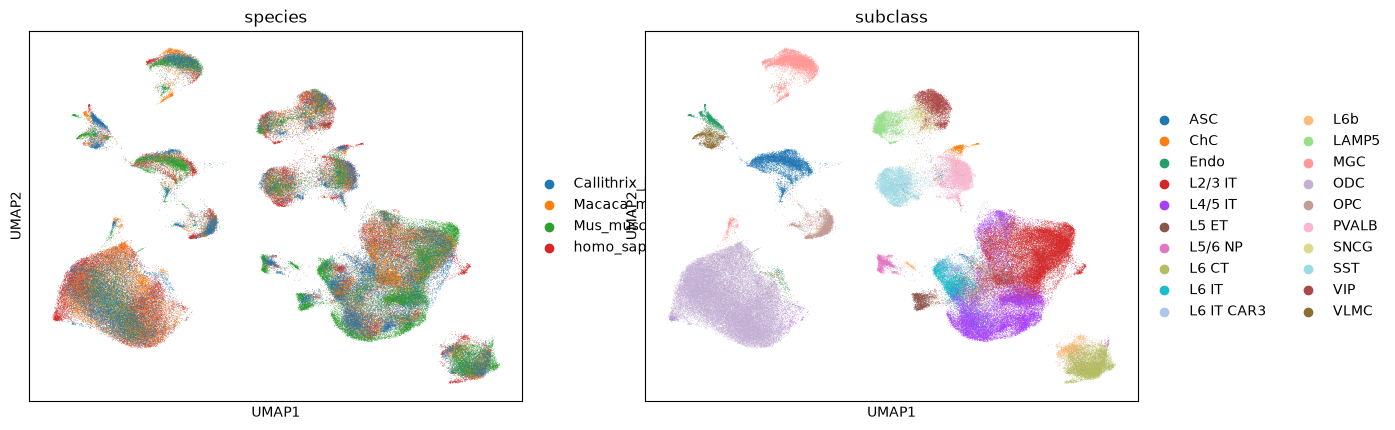

In [24]:
import importlib
import Henosis.evaluate
importlib.reload(Henosis.evaluate)
from Henosis.evaluate import evaluate_integration

integrated_adata = evaluate_integration(
    net,
    test_loader,
    species_to_adata=tokenized,
    #metadata_columns=["cluster"],
    # 如果不同物种列名不一样，改用：
     species_to_metadata_columns={
         "one":["subclass",],
         "homo_sapiens": ["subclass",],
         "Mus_musculus": ["subclass", ],
         "Macaca_mulatta": ["subclass", ],
         "Callithrix_jacchus": ["subclass", ],
     },
    embedding="protein",
    use_mot_correction=True,
    correction_by="inferred_species",
    correction_kwargs={
        "max_rounds": 10,
        "n_clusters": 100,
        "assignment_mode": "sinkhorn",
    },
    umap_colors=["species", "subclass"],
    comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz',
)

In [ ]:
integrated_adata

AnnData object with n_obs × n_vars = 157424 × 64
    obs: 'species', 'subclass', 'inferred_species_token', 'inferred_species'
    uns: 'pca', 'neighbors', 'umap', 'species_colors', 'subclass_colors'
    obsm: 'X_pca', 'X_mot', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [ ]:
species_key = "species"
celltype_key = "subclass"

target_species = [
    "homo_sapiens",
    "Mus_musculus",
    "Macaca_mulatta",
    "Callithrix_jacchus",
]

obs = integrated_adata.obs

# 每个物种包含的细胞类型
celltypes_by_species = {
    species: set(
        obs.loc[obs[species_key] == species, celltype_key]
        .dropna()
        .astype(str)
    )
    for species in target_species
}

# 所有目标物种共有的细胞类型
common_celltypes = sorted(
    set.intersection(*(celltypes_by_species.values()))
)

print(f"共有细胞类型数量：{len(common_celltypes)}")
print(common_celltypes)

共有细胞类型数量：20
['ASC', 'ChC', 'Endo', 'L2/3 IT', 'L4/5 IT', 'L5 ET', 'L5/6 NP', 'L6 CT', 'L6 IT', 'L6 IT CAR3', 'L6b', 'LAMP5', 'MGC', 'ODC', 'OPC', 'PVALB', 'SNCG', 'SST', 'VIP', 'VLMC']


In [ ]:
celltypes_by_species

{'homo_sapiens': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Mus_musculus': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Macaca_mulatta': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'},
 'Callithrix_jacchus': {'ASC',
  'ChC',
  'Endo',
  'L2/3 IT',
  'L4/5 IT',
  'L5 ET',
  'L5/6 NP',
  'L6 CT',
  'L6 IT',
  'L6 IT CAR3',
  'L6b',
  'LAMP5',
  'MGC',
  'ODC',
  'OPC',
  'PVALB',
  'SNCG',
  'SST',
  'VIP',
  'VLMC'}}

In [ ]:
#integrated_adata.write('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure4/motor/hresa_motor_1_64_1.h5ad')

In [ ]:
#adata=sc.read_h5ad('/mnt/public5/panguanyu/cross_species/code/sypy/umap_results/figure4/motor/hresa_motor_1_64_1.h5ad')

In [ ]:
#adata

In [ ]:
'''def attention_score_topk_freq(
    net,
    dataset,
    indices,
    device,
    species_to_embed_file,
    chosen_species,
    csv_path,
    top_k=10,
    top_n=10,
):
    net.eval()
    net.to(device)

    gene_freq = defaultdict(int)

    net.transformer.embed.gene_id(species_to_embed_file)
    raw_map = net.transformer.embed.species_gene_id_map[chosen_species]
    token_to_gene_name = {v: k for k, v in raw_map.items()}

    with torch.no_grad():
        for i in tqdm(indices):

            input_ids = dataset[i]['input_ids'].unsqueeze(0).to(device)
            sp = dataset[i]['sp'].unsqueeze(0).to(device)

            with autocast('cuda'):
                attn_score = net.transformer.attn_score(input_ids, sp)

            attn_score = attn_score.cpu().numpy()[0]   # [L, L]
            input_tokens = input_ids.cpu().numpy()[0]       # [L]

            # column importance: [L]
            cell_gene_importance = attn_score.mean(axis=0)

            # top-k indices
            topk_idx = np.argsort(cell_gene_importance)[-top_k:][::-1]

            for idx in topk_idx:
                token_id = input_tokens[idx]
                if token_id <= 3:
                    continue

                gene_name = token_to_gene_name.get(token_id, f"Unknown_{token_id}")
                gene_freq[gene_name] += 1

    # normalize to frequency
    n_cells = len(indices)
    final_scores = {
        gene: freq / n_cells
        for gene, freq in gene_freq.items()
    }

    sorted_genes = sorted(final_scores.items(), key=lambda x: x[1], reverse=True)

    #top_n = 10
    print(f"\nTop {top_n} Genes by Top-{top_k} Attention Frequency:")

    top_genes=[]
    for rank, (gene, score) in enumerate(sorted_genes[:top_n]):
        print(f"Rank {rank+1}: {gene} (Freq: {score:.4f})")
        top_genes.append(gene)
    
    print(top_genes)
    df = pd.DataFrame(sorted_genes, columns=["gene", "score"])
    df.to_csv(csv_path, index=False)

    return sorted_genes[:top_n]'''

'def attention_score_topk_freq(\n    net,\n    dataset,\n    indices,\n    device,\n    species_to_embed_file,\n    chosen_species,\n    csv_path,\n    top_k=10,\n    top_n=10,\n):\n    net.eval()\n    net.to(device)\n\n    gene_freq = defaultdict(int)\n\n    net.transformer.embed.gene_id(species_to_embed_file)\n    raw_map = net.transformer.embed.species_gene_id_map[chosen_species]\n    token_to_gene_name = {v: k for k, v in raw_map.items()}\n\n    with torch.no_grad():\n        for i in tqdm(indices):\n\n            input_ids = dataset[i][\'input_ids\'].unsqueeze(0).to(device)\n            sp = dataset[i][\'sp\'].unsqueeze(0).to(device)\n\n            with autocast(\'cuda\'):\n                attn_score = net.transformer.attn_score(input_ids, sp)\n\n            attn_score = attn_score.cpu().numpy()[0]   # [L, L]\n            input_tokens = input_ids.cpu().numpy()[0]       # [L]\n\n            # column importance: [L]\n            cell_gene_importance = attn_score.mean(axis=0)\n\n    

In [ ]:
'''import re

cell_type_column = 'subclass'
output_dir = '/mnt/public5/panguanyu/cross_species/gefor/code/tfc'
top_k = 20
top_n = 30
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(output_dir, exist_ok=True)

all_top_results = []
result_manifest = []

for chosen_species, adata in tokenized.items():
    if cell_type_column not in adata.obs.columns:
        print(f'Skip {chosen_species}: obs 中没有 {cell_type_column!r} 列')
        continue

    x_rep = species_to_reps.get(chosen_species, 'X_pca')
    dataset = data.AnndataFastDataset(adata, chosen_species, X_rep=x_rep)
    cell_type_to_indices = defaultdict(list)
    for cell_index, cell_type in enumerate(adata.obs[cell_type_column].tolist()):
        if pd.notna(cell_type):
            cell_type_to_indices[str(cell_type)].append(cell_index)

    for cell_type, indices in tqdm(
        cell_type_to_indices.items(),
        total=len(cell_type_to_indices),
        desc=f'{chosen_species} cell types',
    ):

        safe_cell_type = re.sub(r'[^0-9A-Za-z._-]+', '_', cell_type).strip('_')
        safe_cell_type = safe_cell_type or 'unnamed'
        csv_path = os.path.join(
            output_dir,
            f'{organ}_{chosen_species}_{safe_cell_type}.csv',
        )

        top_results = attention_score_topk_freq(
            net,
            dataset,
            indices,
            device,
            species_to_embed_file,
            chosen_species,
            csv_path,
            top_k=top_k,
            top_n=top_n,
        )

        result_manifest.append({
            'species': chosen_species,
            'cell_type': cell_type,
            'n_cells': len(indices),
            'csv_path': csv_path,
        })
        all_top_results.extend(
            {
                'species': chosen_species,
                'cell_type': cell_type,
                'rank': rank,
                'gene': gene,
                'score': score,
                'n_cells': len(indices),
            }
            for rank, (gene, score) in enumerate(top_results, start=1)
        )

manifest_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_manifest.csv')
summary_path = os.path.join(output_dir, f'{organ}_attention_score_topk_freq_top{top_n}.csv')
pd.DataFrame(result_manifest).to_csv(manifest_path, index=False)
pd.DataFrame(all_top_results).to_csv(summary_path, index=False)
print(f'完成 {len(result_manifest)} 个物种-细胞类型组合')
print(f'清单已保存到: {manifest_path}')
print(f'Top-{top_n} 汇总已保存到: {summary_path}')
pd.DataFrame(result_manifest)'''

"import re\n\ncell_type_column = 'subclass'\noutput_dir = '/mnt/public5/panguanyu/cross_species/gefor/code/tfc'\ntop_k = 20\ntop_n = 30\ndevice = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nos.makedirs(output_dir, exist_ok=True)\n\nall_top_results = []\nresult_manifest = []\n\nfor chosen_species, adata in tokenized.items():\n    if cell_type_column not in adata.obs.columns:\n        print(f'Skip {chosen_species}: obs 中没有 {cell_type_column!r} 列')\n        continue\n\n    x_rep = species_to_reps.get(chosen_species, 'X_pca')\n    dataset = data.AnndataFastDataset(adata, chosen_species, X_rep=x_rep)\n    cell_type_to_indices = defaultdict(list)\n    for cell_index, cell_type in enumerate(adata.obs[cell_type_column].tolist()):\n        if pd.notna(cell_type):\n            cell_type_to_indices[str(cell_type)].append(cell_index)\n\n    for cell_type, indices in tqdm(\n        cell_type_to_indices.items(),\n        total=len(cell_type_to_indices),\n        desc=f'{chosen_spec

In [ ]:
'''from torch.utils.data import DataLoader
import numpy as np
from Henosis.mot_correction import load_comatrix
def gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,batch_size,comatrix_path):
    net.transformer.embed.gene_id(species_to_embed_file)
    net.to(device)
    net.eval()
    #assert set(species_genes.keys())==set(species_to_dataset.keys())
    embeddings=[]
    gene_list=[]
    cells=[]
    sps=[]
    for species in species_genes:
        genes=species_genes[species]
        gene_tokens=[net.transformer.embed.species_gene_id_map[species][gene] for gene in genes]
        raw_map=net.transformer.embed.species_gene_id_map[species]
        token_to_gene_name = {v: k for k, v in raw_map.items()}
        dataset=species_to_dataset[species]
        test_loader=DataLoader(dataset,batch_size=batch_size,shuffle=False,collate_fn=data.h5labelcollate_fn,)

        pbar=tqdm(test_loader,desc='Processing')
        for i,batch in enumerate(pbar):
            with torch.no_grad():
                input_ids,adata,sp,y=batch
                adata=adata.to(device, non_blocking=True)
                input_ids=input_ids.to(device, non_blocking=True)
                sp = sp.to(device, non_blocking=True)
                with autocast('cuda'):
                    attn_embeddings=net.contextual_embed(input_ids,sp)
                batch_embeddings = []
                batch_gene=[]
                batch_cells=[]
                batch_sps=[]
                for gene_token in gene_tokens:
                    token_pos=(input_ids==gene_token)
                    for b in range(input_ids.shape[0]):
                        pos = token_pos[b]
                        emb = attn_embeddings[b][pos]
                        H = attn_embeddings.shape[2]
                        if emb.shape[0] == 0:
                            batch_embeddings.append(torch.zeros(H, device=device))
                        else:
                            batch_embeddings.append(emb.mean(0))
                        batch_cells.append(int(y[b]))
                        batch_gene.append(token_to_gene_name[gene_token])
                        batch_sps.append(token_species_dict[int(sp[b])])
                token_embeddings = torch.stack(batch_embeddings, dim=0)
            embeddings.append(token_embeddings.cpu())
            gene_list+=batch_gene
            cells+=list(test_loader.dataset.le.inverse_transform(batch_cells))
            sps+=batch_sps
    embeddings=torch.cat(embeddings,dim=0)
    #embeddings=F.normalize(embeddings,p=2,dim=1).numpy()
    embeddings=embeddings.numpy()
    types=['gene']*len(embeddings)

    
    adata=sc.AnnData(embeddings)
    adata.obs['cell_type']=cells
    adata.obs['gene']=gene_list
    adata.obs['sp']=sps
    print(adata.shape)
    mask = ~(np.all(adata.X == 0, axis=1))  # True 表示不是全零
    adata = adata[mask].copy()  # 保留非全零的行
    adata.obsm['X_pca_harmony']=load_comatrix(comatrix_path,adata.X.T,adata.obs['sp'])
    print(adata.shape)
    sc.pp.neighbors(adata, use_rep='X_pca_harmony')
    sc.tl.umap(adata)
    n = adata.obs['cell_type'].nunique()
    colors = sns.color_palette("tab20") + sns.color_palette("tab20b") + sns.color_palette("tab20c")
    colors = colors[:n]
    return adata
    '''

'from torch.utils.data import DataLoader\nimport numpy as np\nfrom Henosis.mot_correction import load_comatrix\ndef gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,batch_size,comatrix_path):\n    net.transformer.embed.gene_id(species_to_embed_file)\n    net.to(device)\n    net.eval()\n    #assert set(species_genes.keys())==set(species_to_dataset.keys())\n    embeddings=[]\n    gene_list=[]\n    cells=[]\n    sps=[]\n    for species in species_genes:\n        genes=species_genes[species]\n        gene_tokens=[net.transformer.embed.species_gene_id_map[species][gene] for gene in genes]\n        raw_map=net.transformer.embed.species_gene_id_map[species]\n        token_to_gene_name = {v: k for k, v in raw_map.items()}\n        dataset=species_to_dataset[species]\n        test_loader=DataLoader(dataset,batch_size=batch_size,shuffle=False,collate_fn=data.h5labelcollate_fn,)\n\n        pbar=tqdm(test_loader,desc=\'Processing\')\n        for i,batch in en

In [ ]:
'''species_genes={
    'homo_sapiens':['EGFR','MAF'],
    'Mus_musculus':['Egfr','Maf'],
    'Macaca_mulatta':['EGFR','MAF'],
    'Callithrix_jacchus':['EGFR','MAF'],
}'''
'''species_genes={
    'homo_sapiens':['ERBB4'],
    'Mus_musculus':['Erbb4'],
    'Macaca_mulatta':['ERBB4'],
    'Callithrix_jacchus':['ERBB4'],
}
gene_cell_column='subclass'
species_to_dataset={}
for species,adata in species_to_adata.items():
    if species in species_genes:
        print(f"loading {species}")
        #adata=sc.read_h5ad(h5_file)
        species_to_dataset[species]=data.AnndataLabelDataset(adata,species,cell_column=gene_cell_column,X_rep='X_pca')

device =torch.device('cuda' if torch.cuda.is_available() else 'cpu')'''

'species_genes={\n    \'homo_sapiens\':[\'ERBB4\'],\n    \'Mus_musculus\':[\'Erbb4\'],\n    \'Macaca_mulatta\':[\'ERBB4\'],\n    \'Callithrix_jacchus\':[\'ERBB4\'],\n}\ngene_cell_column=\'subclass\'\nspecies_to_dataset={}\nfor species,adata in species_to_adata.items():\n    if species in species_genes:\n        print(f"loading {species}")\n        #adata=sc.read_h5ad(h5_file)\n        species_to_dataset[species]=data.AnndataLabelDataset(adata,species,cell_column=gene_cell_column,X_rep=\'X_pca\')\n\ndevice =torch.device(\'cuda\' if torch.cuda.is_available() else \'cpu\')'

In [ ]:
'''gene_adata=gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,
            batch_size=64,comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz')'''

"gene_adata=gene_embed_cell_color(species_to_embed_file,species_genes,species_to_dataset,net,device,\n            batch_size=64,comatrix_path=f'/mnt/public5/panguanyu/cross_species/gefor/code/comatrix/{organ}.npz')"

In [ ]:
#gene_adata.obs['gene']=[g.upper() for g in gene_adata.obs['gene']]

In [ ]:
#sc.pl.umap(gene_adata,color=['cell_type','sp','gene'])

In [ ]:
#gene_adata.write('/mnt/public5/panguanyu/cross_species/gefor/code/gene_umap/ERBB4_motor.h5ad')